# Day 31 — K-Means Clustering and Customer Segmentation
**Dataset:** `customer_rfm.csv` · **Goal:** discover useful customer groups without pre-existing labels.

> Run this notebook from top to bottom. Keep `customer_rfm.csv` in the same folder as this notebook, or change `DATA_PATH` in the setup cell. Results can vary slightly with scikit-learn versions, but fixed random seeds make each run reproducible.

**Important business meaning**
- `recency_days`: days since the last purchase (**lower is better**).
- `frequency`: number of purchases (**higher is generally better**).
- `monetary`: total spend in rupees (**higher is generally better**).

Each task has a **code cell first** and a **markdown cell after it** with the key logic, interpretation, and answers to the task-sheet questions.

In [1]:
# SETUP — imports, data loading, and required first checks
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.datasets import make_moons, make_circles

DATA_PATH = "customer_rfm.csv"
df = pd.read_csv(DATA_PATH)

features = ["recency_days", "frequency", "monetary"]
print("HEAD")
display(df.head())
print("\\nSHAPE:", df.shape)
print("\\nINFO")
df.info()
print("\\nMISSING VALUES")
print(df[features].isna().sum())
print("\\nFEATURE RANGES")
display(df[features].agg(["min", "max", "mean", "median", "std"]).T)

X = df[features].to_numpy(dtype=float)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\\nCustomer ID unique:", df["customer_id"].is_unique)
print("All selected feature values finite:", np.isfinite(X).all())

HEAD


,customer_id,recency_days,frequency,monetary
0,CUST00001,342,4,7861.13
1,CUST00002,644,1,3703.22
2,CUST00003,604,2,4582.42
3,CUST00004,424,1,200.00
4,CUST00005,156,8,25822.11


\nSHAPE: (1500, 4)
\nINFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   customer_id   1500 non-null   object 
 1   recency_days  1500 non-null   int64  
 2   frequency     1500 non-null   int64  
 3   monetary      1500 non-null   float64
dtypes: float64(1), int64(2), object(1)
memory usage: 47.0+ KB
\nMISSING VALUES
recency_days    0
frequency       0
monetary        0
dtype: int64
\nFEATURE RANGES


,min,max,mean,median,std
recency_days,1.0,729.00,209.247333,114.50,213.456564
frequency,1.0,29.00,7.249333,6.00,5.927781
monetary,200.0,103858.45,23671.259973,19052.63,20727.730281


\nCustomer ID unique: True
All selected feature values finite: True


## Setup — what the data says
The file has **1,500 customers**, three numeric RFM features, and a customer identifier. The supplied data has no missing values in the three clustering features. `customer_id` is an identifier, not a behavior measurement, so it is excluded from distance calculations.

The observed ranges are printed by the code; recency ranges from **1 to 729 days**, frequency from **1 to 29 purchases**, and monetary spend from **₹200 to about ₹103,858**. These features use different units and ranges, so distance-based K-means should normally use standardized features.

**Why check `head`, `shape`, `info`, missing values, and ranges first?** They verify the file loaded as expected, show the number of rows and columns, reveal data types and missingness, and expose scale differences before modeling.

In [2]:
# TASK 01 — implement K-means from scratch
def kmeans_scratch(X, k, seed=42, max_iters=300, tol=1e-8):
    X = np.asarray(X, dtype=float)
    if X.ndim != 2:
        raise ValueError("X must be a 2D array.")
    if not 1 <= k <= len(X):
        raise ValueError("k must be between 1 and the number of rows.")

    rng = np.random.default_rng(seed)
    centroids = X[rng.choice(len(X), size=k, replace=False)].copy()

    for iteration in range(1, max_iters + 1):
        # ASSIGN: find the distance from each point to each centroid.
        distances = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)
        labels = distances.argmin(axis=1)

        # UPDATE: replace each centroid by the mean of its assigned points.
        new_centroids = centroids.copy()
        for cluster_id in range(k):
            points = X[labels == cluster_id]
            if len(points) > 0:
                new_centroids[cluster_id] = points.mean(axis=0)
            else:
                # Empty cluster: move its centroid to the point farthest from any current centroid.
                nearest_distances = distances.min(axis=1)
                new_centroids[cluster_id] = X[np.argmax(nearest_distances)]

        converged = np.allclose(new_centroids, centroids, rtol=0, atol=tol)
        centroids = new_centroids
        if converged:
            # Reassign once using the final centroids.
            final_distances = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)
            return final_distances.argmin(axis=1), centroids, iteration

    final_distances = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)
    return final_distances.argmin(axis=1), centroids, max_iters

scratch_labels, scratch_centroids, scratch_iterations = kmeans_scratch(
    X_scaled, k=5, seed=42
)
print("Converged/finished after iterations:", scratch_iterations)
print("Cluster counts:", np.bincount(scratch_labels, minlength=5))

Converged/finished after iterations: 18
Cluster counts: [514 340 305 211 130]


## Task 01 — logic and answers
**K-means** is an unsupervised algorithm that partitions observations into *K* groups by repeatedly assigning each observation to its nearest centroid and updating each centroid to the mean of its assigned observations.

- `np.random.default_rng(seed)` makes initialization repeatable.
- `X[:, None, :]` and `centroids[None, :, :]` add dimensions so NumPy can calculate every point-to-centroid distance at once (**broadcasting**).
- `np.linalg.norm(..., axis=2)` calculates Euclidean distance; `argmin(axis=1)` selects the nearest centroid for each customer.
- The update step uses each cluster's mean as its new center.
- **Empty cluster:** this implementation relocates an empty centroid to the point farthest from its nearest current centroid, giving that cluster a chance to receive a point instead of crashing.
- **Why stop when centroids stop moving?** That is a convergence condition: another assign/update round is unlikely to change the solution. A maximum-iteration limit is still kept as a safety guard.
- **Can K-means get worse each iteration?** With ordinary assignment and mean-update steps, the within-cluster sum of squared distances (inertia) should not increase, assuming the steps are implemented correctly. An empty-cluster repair can complicate that guarantee for that iteration, so the implementation should be tested.
- **Why not use a fixed number of iterations alone?** It can stop too early or waste work after convergence. The iteration limit is a safeguard, not the main stopping rule.

**Limitation:** random starting points can lead to different local solutions; K-means is not guaranteed to find the globally best clustering.

In [3]:
# TASK 02 — compare scratch K-means with scikit-learn
# Use init="random" so both methods use random-point initialization rather than sklearn's default k-means++.
scratch_labels, _, scratch_iterations = kmeans_scratch(X_scaled, k=5, seed=42)
library_model = KMeans(n_clusters=5, init="random", n_init=1, random_state=42, max_iter=300)
library_labels = library_model.fit_predict(X_scaled)

agreement_ari = adjusted_rand_score(scratch_labels, library_labels)
print(f"Adjusted Rand Index (scratch vs sklearn): {agreement_ari:.4f}")
print("Scratch iterations:", scratch_iterations)
print("Scratch counts:", np.bincount(scratch_labels, minlength=5))
print("Library counts:", np.bincount(library_labels, minlength=5))

Adjusted Rand Index (scratch vs sklearn): 1.0000
Scratch iterations: 18
Scratch counts: [514 340 305 211 130]
Library counts: [340 305 514 130 211]


## Task 02 — logic and answer
The **Adjusted Rand Index (ARI)** compares two clusterings by measuring whether pairs of observations are grouped together or separately in both results, adjusted for chance. ARI is **1.0** for identical partitions, approximately **0** for chance-level agreement, and can be negative for worse-than-chance agreement.

Do not compare label arrays with `==`: cluster number 0 has no inherent meaning. If one implementation calls a group “0” and the other calls that exact same group “3”, the partitions can still be identical. With the same random initialization strategy and seed, the ARI should be **1.0000** for this dataset if both implementations follow the same algorithmic steps. Small implementation differences or ties can alter this.

**Why `init="random"` here?** Scikit-learn defaults to k-means++ initialization, while the scratch version samples data points uniformly. Matching the initialization strategy makes this a fairer implementation check. In real modeling, k-means++ is usually the stronger default.

ARI (unscaled vs scaled): 0.3805


recency_days                   ...   monetary                   
                 min  max        mean  ...        max          mean size
cluster                                ...                              
0                  1  107   31.500000  ...   62538.72  50609.210225  178
1                 13  729  449.728682  ...   11555.20   4818.147558  516
2                  2  109   55.277778  ...  103858.45  74793.580648  108
3                  1  299   61.556420  ...   39894.99  29925.774241  257
4                  4  299  123.387755  ...   24271.12  18693.096848  441

[5 rows x 12 columns]

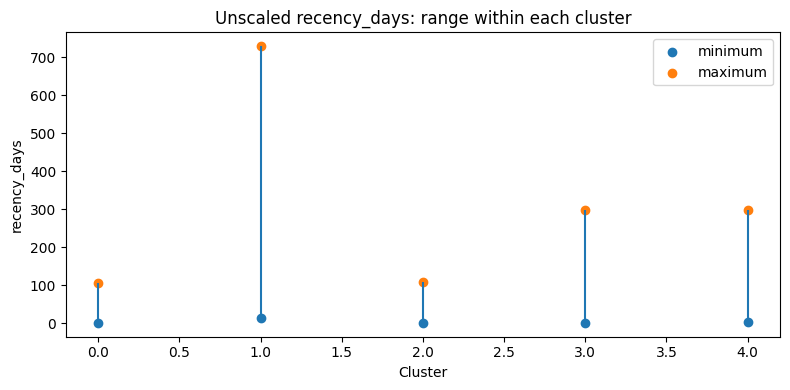

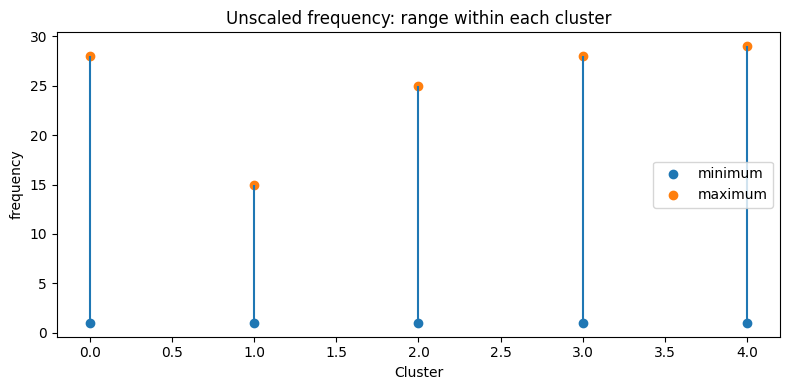

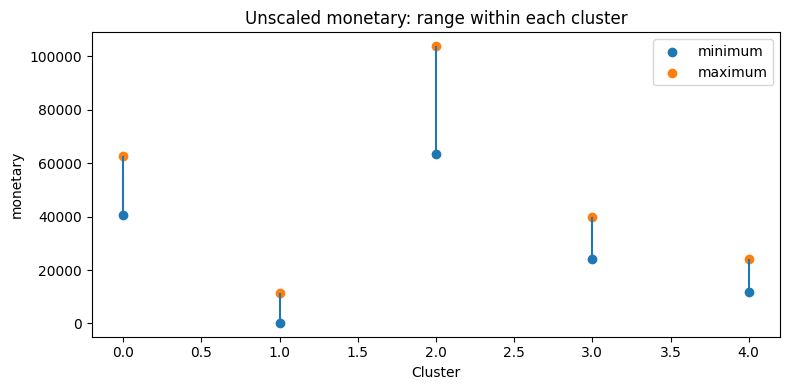

In [4]:
# TASK 03 — compare unscaled and standardized features
raw_model = KMeans(n_clusters=5, random_state=42, n_init=10)
raw_labels = raw_model.fit_predict(X)
scaled_model = KMeans(n_clusters=5, random_state=42, n_init=10)
scaled_labels = scaled_model.fit_predict(X_scaled)

print("ARI (unscaled vs scaled):", round(adjusted_rand_score(raw_labels, scaled_labels), 4))

raw_profile = df[features].copy()
raw_profile["cluster"] = raw_labels
range_table = raw_profile.groupby("cluster")[features].agg(["min", "max", "mean", "size"])
display(range_table)

# Visualize the raw cluster ranges for each feature.
for feature in features:
    grouped = raw_profile.groupby("cluster")[feature]
    mins, maxs = grouped.min(), grouped.max()
    plt.figure(figsize=(8, 4))
    plt.vlines(mins.index, mins.values, maxs.values)
    plt.scatter(mins.index, mins.values, label="minimum")
    plt.scatter(maxs.index, maxs.values, label="maximum")
    plt.title(f"Unscaled {feature}: range within each cluster")
    plt.xlabel("Cluster")
    plt.ylabel(feature)
    plt.legend()
    plt.tight_layout()
    plt.show()

## Task 03 — logic and answer
**Standardization** converts each feature to approximately mean 0 and standard deviation 1. K-means uses Euclidean distance, so a feature with a much larger numeric range can dominate the distance if features are not scaled.

The raw monetary values are in the hundreds to over one hundred thousand rupees, while frequency is only 1–29. Consequently, unscaled clustering is strongly influenced by **monetary spend**; recency and frequency can have much less influence on which points are considered close. The ARI and the per-cluster ranges above show how much the assignments differ after scaling.

**Future-project risk:** features such as income in rupees, transaction amount, population, or distance in meters can dominate smaller-range features unless scaling or a deliberate weighting scheme is used.

**Why standardize rather than min-max scale?** StandardScaler is a common baseline for K-means because Euclidean distances are then based on standard-deviation units. Min-max scaling is also valid, but is more sensitive to extreme minimum/maximum values. Neither scaler automatically makes a feature more important in business terms; scaling is a modeling choice.

In [5]:
# TASK 04 — skewness, log1p transform, clustering, and profiles
print("Feature skewness (positive means a longer right tail):")
display(df[features].skew().rename("skewness").to_frame())

log_data = df[features].copy()
log_data[["frequency", "monetary"]] = np.log1p(log_data[["frequency", "monetary"]])
X_log_scaled = StandardScaler().fit_transform(log_data)

labels_original_scaled = KMeans(n_clusters=5, random_state=42, n_init=10).fit_predict(X_scaled)
labels_log_scaled = KMeans(n_clusters=5, random_state=42, n_init=10).fit_predict(X_log_scaled)

print("ARI (original scaled vs log1p scaled):",
      round(adjusted_rand_score(labels_original_scaled, labels_log_scaled), 4))
print("Silhouette — original scaled:",
      round(silhouette_score(X_scaled, labels_original_scaled), 4))
print("Silhouette — log1p then scaled:",
      round(silhouette_score(X_log_scaled, labels_log_scaled), 4))

def make_profile(labels):
    temp = df[features].copy()
    temp["cluster"] = labels
    profile = temp.groupby("cluster")[features].mean()
    profile["customers"] = temp.groupby("cluster").size()
    profile["percent"] = 100 * profile["customers"] / len(temp)
    return profile.round(2)

print("Original scaled clustering profile (original units):")
display(make_profile(labels_original_scaled))
print("Log1p-scaled clustering profile (reported in original units):")
display(make_profile(labels_log_scaled))

Feature skewness (positive means a longer right tail):


,skewness
recency_days,0.959705
frequency,1.181868
monetary,1.226394


ARI (original scaled vs log1p scaled): 0.4683
Silhouette — original scaled: 0.4417
Silhouette — log1p then scaled: 0.3621
Original scaled clustering profile (original units):


,recency_days,frequency,monetary,customers,percent
cluster,,,,,
0,65.40,4.01,68078.29,130,8.67
1,562.94,2.09,4142.34,324,21.60
2,249.85,4.10,12527.44,356,23.73
3,20.14,18.93,46920.58,207,13.80
4,61.82,8.90,23068.87,483,32.20


Log1p-scaled clustering profile (reported in original units):


,recency_days,frequency,monetary,customers,percent
cluster,,,,,
0,71.43,3.48,59955.55,154,10.27
1,599.19,2.02,3938.38,252,16.80
2,125.40,7.11,19717.05,532,35.47
3,342.82,2.41,5391.69,222,14.80
4,26.65,16.22,39984.82,340,22.67


## Task 04 — logic, decision, and answers
**Skewness** describes asymmetry in a distribution. The three features are positively skewed in this dataset, with frequency and monetary especially right-skewed. A few customers have unusually high purchase counts or spending.

`np.log1p(x)` calculates `log(1 + x)`. It is safer than `log(x)` when zeros may occur because `log1p(0) = 0`; plain `log(0)` is undefined. Here the observed frequency and monetary values are positive, but `log1p` is still a convenient robust pattern. The transformation compresses large values more than small values; it does **not** remove skew automatically or make every distribution normal.

**Observed evidence in this dataset:** the original standardized K=5 solution has silhouette around **0.4417**, while log1p-then-standardize has silhouette around **0.3621**; the ARI between the two partitions is around **0.4683**. These are meaningfully different segmentations.

**Decision to carry forward:** use the **original features after StandardScaler** as the main solution because its silhouette is higher and its clusters retain a direct relationship to the original RFM values. This is not a universal rule: if the business wants to reduce the influence of extreme spenders, the log version may be preferable despite a lower silhouette. The cost of rejecting the log version is that a small number of high-spend customers may exert more influence on the grouping.

**What can enormous spenders do without a transform?** They can pull centroids toward themselves and cause clusters to be organized around spend levels, potentially hiding useful differences among the rest of the customers.

,K,inertia,silhouette
0,2,2233.0572,0.4426
1,3,1447.7007,0.4595
2,4,873.3661,0.5135
3,5,669.2140,0.4417
4,6,564.1963,0.3917
5,7,485.6458,0.3948
6,8,433.3824,0.3852
7,9,393.1342,0.3741
8,10,360.5544,0.3600


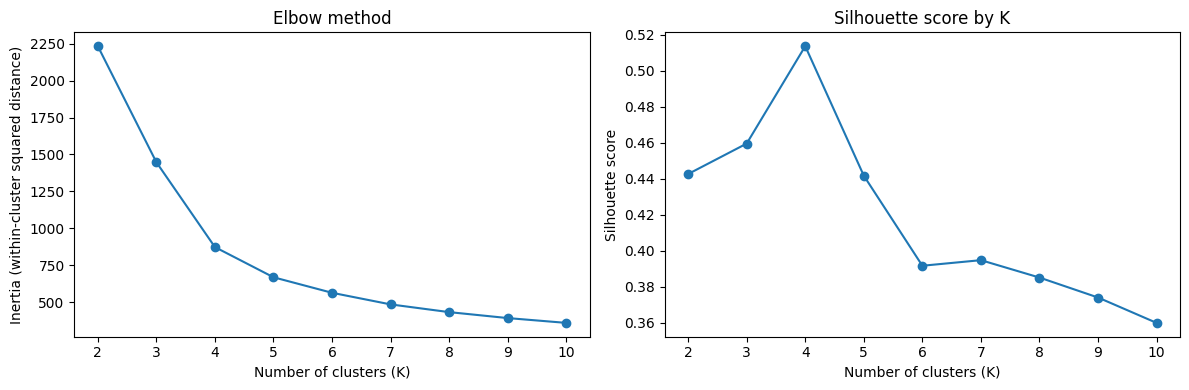

Highest silhouette K: 4


In [6]:
# TASK 05 — elbow and silhouette for K=2..10
k_values = range(2, 11)
inertias, silhouettes = [], []
models_by_k = {}

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    models_by_k[k] = (model, labels)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

metrics = pd.DataFrame({"K": list(k_values), "inertia": inertias, "silhouette": silhouettes})
display(metrics.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(metrics["K"], metrics["inertia"], marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia (within-cluster squared distance)")
axes[1].plot(metrics["K"], metrics["silhouette"], marker="o")
axes[1].set_title("Silhouette score by K")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette score")
plt.tight_layout()
plt.show()

best_silhouette_k = int(metrics.loc[metrics["silhouette"].idxmax(), "K"])
print("Highest silhouette K:", best_silhouette_k)

## Task 05 — logic and answer
**Inertia** is the sum of squared distances from each observation to its assigned centroid. It always tends to fall as K increases, so the elbow plot looks for a point after which extra clusters give diminishing improvement. The elbow can be subjective.

The **silhouette score** compares how close a point is to its own cluster versus the nearest other cluster. It ranges from −1 to 1; higher values generally indicate better-separated, compact groups under the chosen distance measure.

**Observed result:** on the original standardized features, the highest silhouette in K=2…10 is expected at **K=4** (about **0.5135** for this run). The elbow is not a perfect automatic answer; use the plotted curve and table to identify where inertia improvement starts slowing. The methods need not agree: silhouette prefers geometric separation, while elbow emphasizes diminishing returns in compactness.

**Which should you trust more?** Neither automatically. Use both to shortlist candidate values, then inspect cluster profiles and ask whether the groups imply meaningfully different business actions.

In [7]:
# TASK 06 — compare K preferred by silhouette (4) with K one above it (5)
k_small, k_large = best_silhouette_k, best_silhouette_k + 1
labels_small = models_by_k[k_small][1]
labels_large = models_by_k[k_large][1]

print(f"K={k_small} profile:")
display(make_profile(labels_small))
print(f"K={k_large} profile:")
display(make_profile(labels_large))
print("ARI between the K=4 and K=5 partitions:",
      round(adjusted_rand_score(labels_small, labels_large), 4))

# Cross-tab shows which K=5 segments are grouped together by K=4.
cross_tab = pd.crosstab(
    pd.Series(labels_small, name=f"K={k_small} cluster"),
    pd.Series(labels_large, name=f"K={k_large} cluster")
)
print("Cross-tab: K=4 cluster membership by K=5 cluster")
display(cross_tab)

K=4 profile:


,recency_days,frequency,monetary,customers,percent
cluster,,,,,
0,492.49,2.14,4357.95,453,30.20
1,65.40,4.01,68078.29,130,8.67
2,113.48,7.44,20740.09,682,45.47
3,20.77,18.34,44841.79,235,15.67


K=5 profile:


,recency_days,frequency,monetary,customers,percent
cluster,,,,,
0,65.40,4.01,68078.29,130,8.67
1,562.94,2.09,4142.34,324,21.60
2,249.85,4.10,12527.44,356,23.73
3,20.14,18.93,46920.58,207,13.80
4,61.82,8.90,23068.87,483,32.20


ARI between the K=4 and K=5 partitions: 0.5804
Cross-tab: K=4 cluster membership by K=5 cluster


K=5 cluster,0,1,2,3,4
K=4 cluster,,,,,
0,0,324,129,0,0
1,130,0,0,0,0
2,0,0,227,0,455
3,0,0,0,207,28


## Task 06 — business decision and answers
The silhouette-preferred value is **K=4**, so this task compares K=4 with K=5. In this dataset, K=4 combines customers that K=5 separates into a less-recent/lower-frequency/lower-spend group and a more-recent/more-frequent/medium-spend group. Those customers may need different actions: reactivation offers for less-recent customers versus loyalty or cross-sell offers for more active customers.

**Decision: carry K=5 forward** if the marketing team has the capacity to target five groups separately. This deliberately overrules the silhouette preference because the extra group supports a distinct action. What we give up is a cleaner geometric separation (the silhouette is lower) and a simpler campaign plan. If the business cannot execute five different campaigns, K=4 may be more practical.

**Why not K=12 just because clusters get tighter?** More groups can fragment the audience into tiny, expensive-to-manage segments and make the differences too small to support distinct actions. The analyst should explain the trade-offs and evidence; the business owner should make the final decision based on campaign capacity, cost, and customer strategy.

**One-sentence justification:** *We use five segments because the additional segment separates less-active customers from recently active customers who merit different marketing actions.*

In [8]:
# TASK 07 — name the segments and recommend actions
# Fit the selected K=5 model and create a profile in original feature units.
final_k = 5
final_model = KMeans(n_clusters=final_k, random_state=42, n_init=10)
final_labels = final_model.fit_predict(X_scaled)

final_profile = make_profile(final_labels)
display(final_profile)

# Names are based on the measured profile, not on cluster numbers.
segment_names = {
    0: "High-spend, low-frequency recent customers",
    1: "Dormant, low-spend customers",
    2: "Lapsed / mid-value customers",
    3: "Champions",
    4: "Active, regular customers",
}
segment_actions = {
    0: "Offer a personal follow-up or premium cross-sell; investigate why spend is high despite fewer purchases.",
    1: "Use a low-cost win-back message; suppress expensive incentives if response is poor.",
    2: "Run a targeted reactivation campaign and test a modest return incentive.",
    3: "Prioritize retention, VIP service, and referral/advocacy offers.",
    4: "Encourage repeat purchases with loyalty rewards and relevant cross-sells.",
}
named_profile = final_profile.copy()
named_profile.insert(0, "segment_name", [segment_names[i] for i in named_profile.index])
named_profile["recommended_action"] = [segment_actions[i] for i in named_profile.index]
display(named_profile)

print("Priority ranking (starting recommendation):")
priority_order = [3, 0, 4, 2, 1]
for rank, cluster_id in enumerate(priority_order, start=1):
    row = final_profile.loc[cluster_id]
    print(f"{rank}. {segment_names[cluster_id]} — {int(row['customers'])} customers "
          f"({row['percent']:.1f}%). Mean recency={row['recency_days']:.1f} days, "
          f"frequency={row['frequency']:.1f}, spend=₹{row['monetary']:.0f}. "
          f"Action: {segment_actions[cluster_id]}")

,recency_days,frequency,monetary,customers,percent
cluster,,,,,
0,65.40,4.01,68078.29,130,8.67
1,562.94,2.09,4142.34,324,21.60
2,249.85,4.10,12527.44,356,23.73
3,20.14,18.93,46920.58,207,13.80
4,61.82,8.90,23068.87,483,32.20


,segment_name,recency_days,frequency,monetary,customers,percent,recommended_action
cluster,,,,,,,
0,"High-spend, low-frequency recent customers",65.40,4.01,68078.29,130,8.67,Offer a personal follow-up or premium cross-se...
1,"Dormant, low-spend customers",562.94,2.09,4142.34,324,21.60,Use a low-cost win-back message; suppress expe...
2,Lapsed / mid-value customers,249.85,4.10,12527.44,356,23.73,Run a targeted reactivation campaign and test ...
3,Champions,20.14,18.93,46920.58,207,13.80,"Prioritize retention, VIP service, and referra..."
4,"Active, regular customers",61.82,8.90,23068.87,483,32.20,Encourage repeat purchases with loyalty reward...


Priority ranking (starting recommendation):
1. Champions — 207 customers (13.8%). Mean recency=20.1 days, frequency=18.9, spend=₹46921. Action: Prioritize retention, VIP service, and referral/advocacy offers.
2. High-spend, low-frequency recent customers — 130 customers (8.7%). Mean recency=65.4 days, frequency=4.0, spend=₹68078. Action: Offer a personal follow-up or premium cross-sell; investigate why spend is high despite fewer purchases.
3. Active, regular customers — 483 customers (32.2%). Mean recency=61.8 days, frequency=8.9, spend=₹23069. Action: Encourage repeat purchases with loyalty rewards and relevant cross-sells.
4. Lapsed / mid-value customers — 356 customers (23.7%). Mean recency=249.8 days, frequency=4.1, spend=₹12527. Action: Run a targeted reactivation campaign and test a modest return incentive.
5. Dormant, low-spend customers — 324 customers (21.6%). Mean recency=562.9 days, frequency=2.1, spend=₹4142. Action: Use a low-cost win-back message; suppress expensive ince

## Task 07 — names, numbers, actions, and priority
Use the printed profile table as the source of truth for each segment's mean recency, frequency, monetary spend, count, and percentage. Cluster numbers are arbitrary, so the names in this notebook are tied to the K=5 run with `random_state=42` and should always be checked against the displayed profile.

**How to justify a name:** cite the row's actual numbers. “Champions” is defensible only when the row shows very recent purchasing, high purchase frequency, and high spend. Recency must be read in reverse: a lower number means a more recent purchase.

**Starting priority ranking:** (1) Champions — protect high-value relationships; (2) high-spend customers — preserve substantial revenue and learn what drives their high spend; (3) active regular customers — encourage retention and repeat buying; (4) lapsed/mid-value customers — test reactivation; (5) dormant/low-spend customers — start with low-cost outreach. This ranking is a business proposal, not a mathematical truth; campaign cost, margins, and response history could change it.

In [9]:
# TASK 08 — stability across 10 random seeds
def stability_scores(k, n_init):
    label_runs = []
    for seed in range(10):
        model = KMeans(n_clusters=k, random_state=seed, n_init=n_init)
        label_runs.append(model.fit_predict(X_scaled))
    # Compare each run to run 0; ARI does not care about arbitrary label numbering.
    scores = [adjusted_rand_score(label_runs[0], labels) for labels in label_runs[1:]]
    return np.array(scores)

stability_rows = []
for n_init in [1, 10]:
    scores = stability_scores(final_k, n_init)
    stability_rows.append({
        "n_init": n_init,
        "minimum_ARI_vs_first_run": scores.min(),
        "maximum_ARI_vs_first_run": scores.max(),
        "mean_ARI_vs_first_run": scores.mean()
    })
stability_table = pd.DataFrame(stability_rows).round(4)
display(stability_table)

,n_init,minimum_ARI_vs_first_run,maximum_ARI_vs_first_run,mean_ARI_vs_first_run
0,1,0.8945,1.0,0.9808
1,10,0.9941,1.0,0.9987


## Task 08 — logic and answer
**Stability** asks whether a model discovers nearly the same partition when randomness changes. `n_init=1` tries one initialization; `n_init=10` runs ten initializations and keeps the best solution by inertia for each seed. ARI compares each seed's labels with the first run's labels.

For this dataset and K=5, the results should show high agreement even with `n_init=1`, and typically very high agreement with `n_init=10`; use the exact minimum/maximum printed above in your report. **Recommendation:** use `n_init=10` as a reasonable production baseline, or a larger value if the additional computation is inexpensive and stability is critical.

High stability does not prove the segments are meaningful or fair; it only says the algorithm tends to reproduce the same partition under the tested initializations. Recheck stability when data, features, scaling, or K changes.

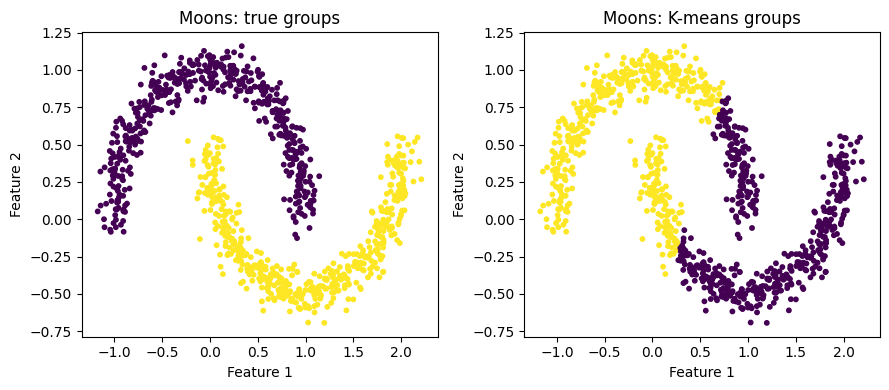

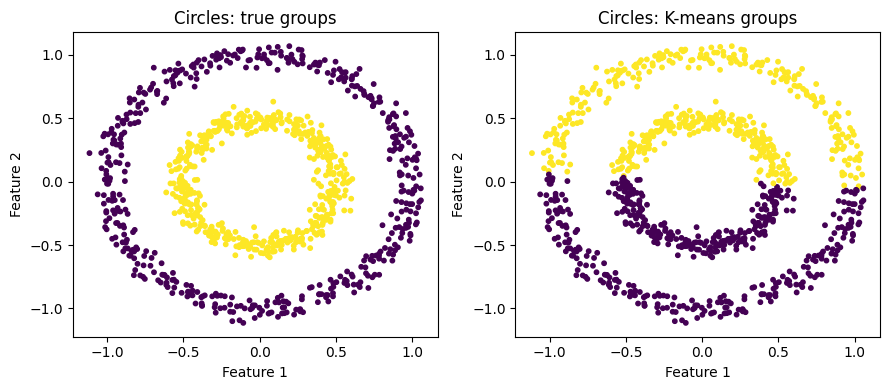

,dataset,ARI_vs_true_groups,silhouette
0,Moons,0.2433,0.4852
1,Circles,-0.0010,0.3541


In [10]:
# TASK 09 — demonstrate where K-means struggles: moons and circles
toy_results = []

X_moons, y_moons = make_moons(n_samples=1000, noise=0.08, random_state=42)
X_circles, y_circles = make_circles(n_samples=1000, noise=0.05, factor=0.5, random_state=42)

for name, X_toy, y_true in [
    ("Moons", X_moons, y_moons),
    ("Circles", X_circles, y_circles),
]:
    predicted = KMeans(n_clusters=2, random_state=42, n_init=10).fit_predict(X_toy)
    ari = adjusted_rand_score(y_true, predicted)
    sil = silhouette_score(X_toy, predicted)
    toy_results.append({"dataset": name, "ARI_vs_true_groups": ari, "silhouette": sil})

    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    axes[0].scatter(X_toy[:, 0], X_toy[:, 1], c=y_true, s=10)
    axes[0].set_title(f"{name}: true groups")
    axes[0].set_xlabel("Feature 1")
    axes[0].set_ylabel("Feature 2")
    axes[1].scatter(X_toy[:, 0], X_toy[:, 1], c=predicted, s=10)
    axes[1].set_title(f"{name}: K-means groups")
    axes[1].set_xlabel("Feature 1")
    axes[1].set_ylabel("Feature 2")
    plt.tight_layout()
    plt.show()

display(pd.DataFrame(toy_results).round(4))

## Task 09 — failure explanation and warning
`make_moons` creates two curved, interlocking groups; `make_circles` creates an inner ring and outer ring. K-means uses distances to centroids and tends to create convex, roughly round partitions, so a straight boundary or centroid-based split cannot represent these shapes well.

The printed ARI compares K-means with the known generated labels; the silhouette only evaluates compactness/separation under the predicted clustering's geometry. For moons, silhouette can look moderately healthy even while ARI shows poor recovery of the true groups. For circles, the silhouette may also be positive even though the ARI is near zero.

**Two-sentence warning to a teammate:** *A healthy silhouette score does not prove that the clusters correspond to the real or useful groups you care about. Always plot and profile the clusters, compare with known labels when available, test stability, and ask a domain expert whether the groups lead to distinct actions.*

**What to do instead:** combine geometry scores with visual inspection, domain/business validation, stability checks, and (where possible) external labels or downstream outcomes. DBSCAN or spectral clustering may better capture non-spherical shapes, but each has its own assumptions and tuning choices.

In [11]:
# TASK 10 — generate a plain-language one-page marketing brief
# Build the brief from the final K=5 profile so its numbers stay tied to the model.
brief_lines = [
    "TO: Head of Marketing",
    "SUBJECT: Customer groups and recommended next actions",
    "",
    "We grouped 1,500 customers using how recently they purchased, how often they purchased, and how much they spent. "
    "We recommend starting with five groups: four groups were simpler, but combined customers who may need different "
    "campaigns; additional groups would add complexity without clear evidence that the team could act on every small difference.",
    "",
]
for cluster_id in priority_order:
    row = final_profile.loc[cluster_id]
    brief_lines.append(
        f"{segment_names[cluster_id]} — {int(row['customers'])} customers "
        f"({row['percent']:.1f}%). On average they last purchased {row['recency_days']:.0f} days ago, "
        f"bought {row['frequency']:.1f} times, and spent ₹{row['monetary']:,.0f}. "
        f"Next action: {segment_actions[cluster_id]}"
    )
    brief_lines.append("")

brief_lines.extend([
    "First action: start with Champions, because they purchase recently, frequently, and at high spend; protecting these relationships may preserve valuable business.",
    "Honest limitation: these groups describe past behavior, not why a customer behaved that way, and the groups do not prove who will respond to a campaign.",
    "Refresh plan: review the groups monthly or quarterly, depending on purchase volume. Re-run after meaningful changes because new purchases change recency and frequency, spending changes over time, and customer behavior can shift.",
])
brief_text = "\\n".join(brief_lines)
print(brief_text)

TO: Head of Marketing\nSUBJECT: Customer groups and recommended next actions\n\nWe grouped 1,500 customers using how recently they purchased, how often they purchased, and how much they spent. We recommend starting with five groups: four groups were simpler, but combined customers who may need different campaigns; additional groups would add complexity without clear evidence that the team could act on every small difference.\n\nChampions — 207 customers (13.8%). On average they last purchased 20 days ago, bought 18.9 times, and spent ₹46,921. Next action: Prioritize retention, VIP service, and referral/advocacy offers.\n\nHigh-spend, low-frequency recent customers — 130 customers (8.7%). On average they last purchased 65 days ago, bought 4.0 times, and spent ₹68,078. Next action: Offer a personal follow-up or premium cross-sell; investigate why spend is high despite fewer purchases.\n\nActive, regular customers — 483 customers (32.2%). On average they last purchased 62 days ago, bought

## Task 10 — brief notes and quality check
The code prints a plain-language brief with the five segment sizes, average behavior, recommended actions, first priority, one limitation, and a refresh schedule. Review it before sharing: the best refresh interval depends on how frequently customers purchase and how quickly marketing campaigns change.

**Business limitation:** clustering describes patterns; it does not establish causes or guarantee that a campaign will work. A follow-up experiment or campaign A/B test is needed to measure actual lift.

**Final checklist**
- Run the notebook top-to-bottom in a fresh kernel.
- Keep `customer_rfm.csv` beside the notebook or update `DATA_PATH`.
- Check every segment name against its profile row.
- Verify plots have titles and labelled axes.
- Report the actual numbers generated by your environment, not guessed values.
- Be able to explain the alternative rejected for each decision.

# After the required tasks — core concepts in plain language

## 1. What is clustering?
In supervised learning, examples come with answers (labels). In clustering, the algorithm only sees feature values and tries to group similar rows. K-means always creates the requested number of groups, even when the data has no natural groups.

## 2. What is a centroid?
A centroid is the average position of the observations in a cluster. It may not be an actual customer; it is a mathematical representative of the group.

## 3. What is Euclidean distance?
For two points, Euclidean distance is the straight-line distance between them. In multiple dimensions, it combines feature-wise differences. Because differences are squared, large numeric differences can dominate, which is why scaling matters.

## 4. Why scale?
If spend ranges up to 100,000 but frequency ranges only up to 29, raw distance can mostly measure spend. StandardScaler expresses each feature in standard-deviation units. Scaling is not always mandatory, but for K-means with features in different units it is a strong default.

## 5. Why can skew matter after scaling?
Standardization changes location and spread, but it does not remove a long right tail. Log transformation compresses high values. That changes the geometry and can change cluster membership, so compare profiles and scores rather than applying a transform blindly.

## 6. What does K control?
K is the number of clusters requested. A small K gives simpler, broader groups; a larger K gives more detailed but potentially harder-to-use groups. The best K depends on geometry and the business's ability to take different actions.

## 7. What do the metrics mean?
- **Inertia:** how close observations are to their assigned centroids; lower usually comes with more clusters.
- **Silhouette:** how well-separated and compact clusters look according to distance; higher is generally better, but it does not prove business meaning.
- **ARI:** agreement between two partitions or between predicted and known groups; useful when label names are arbitrary.
- **Stability:** whether repeated runs find similar groups.

## 8. Why K-means and not another algorithm?
K-means is fast, straightforward, and interpretable, but works best for reasonably compact, centroid-representable groups. Hierarchical clustering can show nested group structure but can be more expensive. DBSCAN can find irregular shapes and noise points but needs density parameters and may struggle when densities differ. Gaussian mixture models allow soft membership but assume a mixture distribution. The right choice depends on the data and goal.

## 9. Advantages and limitations
**Advantages:** relatively simple, scalable, easy to profile, and fast on many numeric datasets.  
**Limitations:** requires K in advance; sensitive to scaling, outliers, initialization, and feature choice; prefers roughly convex clusters; and does not tell you whether a group is commercially valuable.

## 10. Why inspect clusters before deploying?
A score is only a summary of geometry. Inspect actual averages, ranges, sizes, and examples; confirm the segment names match the numbers; and validate that each group deserves a different action. Then measure whether those actions improve business outcomes.